# Tugas Praktikum 4: Association Rule
**Nama:** Prima Surya Nusantara  
**NRP:** 5054251036  
**Metode:** FP-Growth, seluruh negara pada Online Retail.

Tujuan: menemukan produk yang muncul bersama pada invoice dan mengevaluasi support, confidence, serta lift.

In [ ]:
from pathlib import Path
import json, math, platform
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules
from IPython.display import display, Image, Markdown
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 12)
OUT = Path.cwd()
DATA = "Online Retail.xlsx"
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| mlxtend:', mlxtend.__version__)

Python: 3.14.5 | pandas: 3.0.6 | mlxtend: 0.25.0


## 1. Import dan eksplorasi dataset
Satu baris merupakan satu baris produk dalam invoice. InvoiceNo menjadi unit transaksi, sedangkan Description menjadi identitas item sesuai instruksi. CustomerID tidak diperlukan untuk pengelompokan invoice.

In [4]:
df = pd.read_excel(DATA, engine='openpyxl')
display(df.head())
print('Shape:', df.shape)
df.info()
display(df.isna().sum().rename('Jumlah kosong').to_frame())
print('Periode:', df.InvoiceDate.min(), 's.d.', df.InvoiceDate.max())
print('Negara:', df.Country.nunique(), '| Invoice awal:', df.InvoiceNo.nunique())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Shape: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


,Jumlah kosong
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Periode: 2010-12-01 08:26:00 s.d. 2011-12-09 12:50:00
Negara: 38 | Invoice awal: 25900


## 2. Pembersihan data
Penghapusan dilakukan berurutan agar jumlah baris yang dihapus tidak dihitung ganda. Description dibersihkan dari spasi tepi; nilai kosong, invoice pembatalan berawalan C, dan Quantity <= 0 dikeluarkan. CustomerID kosong, harga nol, dan seluruh negara tetap dipertahankan sesuai ruang lingkup tugas. Baris berulang tidak memengaruhi kehadiran item karena setiap invoice memakai himpunan produk unik.

In [5]:
clean = df.copy()
audit = []
def record(stage, before):
    audit.append({'Tahap': stage, 'Baris': len(clean), 'Invoice': clean.InvoiceNo.nunique(), 'Dihapus': before-len(clean)})
record('Data awal', len(clean))
clean['Description'] = clean.Description.astype('string').str.strip()
n = len(clean)
clean = clean.loc[clean.Description.notna() & clean.Description.ne('')].copy()
record('Description kosong', n)
clean['InvoiceNo'] = clean.InvoiceNo.astype(str).str.strip()
n = len(clean)
clean = clean.loc[~clean.InvoiceNo.str.upper().str.startswith('C')].copy()
record('Invoice pembatalan C', n)
n = len(clean)
clean = clean.loc[clean.Quantity.gt(0)].copy()
record('Quantity <= 0', n)
audit = pd.DataFrame(audit)
display(audit)
display(clean.Description.value_counts().head(10).rename('Baris produk').to_frame())
print('CustomerID kosong dipertahankan:', clean.CustomerID.isna().sum())

,Tahap,Baris,Invoice,Dihapus
0,Data awal,541909,25900,0
1,Description kosong,540455,24446,1454
2,Invoice pembatalan C,531167,20610,9288
3,Quantity <= 0,530693,20136,474


,Baris produk
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2327
JUMBO BAG RED RETROSPOT,2115
REGENCY CAKESTAND 3 TIER,2019
PARTY BUNTING,1707
LUNCH BAG RED RETROSPOT,1594
ASSORTED COLOUR BIRD ORNAMENT,1489
SET OF 3 CAKE TINS PANTRY DESIGN,1399
PACK OF 72 RETROSPOT CAKE CASES,1370
LUNCH BAG BLACK SKULL.,1328


CustomerID kosong dipertahankan: 132769


## 3. Transaksi dan one-hot basket
Setiap invoice menjadi satu keranjang. Pembelian beberapa unit produk dihitung sebagai satu kehadiran. Basket sparse boolean menghemat memori dan tetap memuat seluruh item dan invoice. Jumlah transaksi, bukan jumlah baris maupun unit, menjadi penyebut support.

In [6]:
transactions = clean.groupby('InvoiceNo', sort=True)['Description'].agg(lambda s: sorted(set(s)))
te = TransactionEncoder()
encoded = te.fit(transactions.tolist()).transform(transactions.tolist(), sparse=True)
basket = pd.DataFrame.sparse.from_spmatrix(encoded, index=transactions.index, columns=te.columns_)
display(transactions.head().to_frame('Produk unik'))
display(basket.iloc[:5, :8])
print('Ukuran basket:', basket.shape)
print('Kepadatan:', encoded.nnz / (basket.shape[0] * basket.shape[1]))
display(transactions.map(len).describe().to_frame('Produk unik per invoice'))
transactions.rename('Items').map(json.dumps).to_csv(OUT/'transaksi_bersih.csv', encoding='utf-8-sig')
from scipy.sparse import save_npz
save_npz(OUT/'basket_onehot.npz', encoded)
(OUT/'basket_labels.json').write_text(json.dumps({'invoices': transactions.index.tolist(), 'products': te.columns_}, ensure_ascii=False), encoding='utf-8')

,Produk unik
InvoiceNo,
536365,"[CREAM CUPID HEARTS COAT HANGER, GLASS STAR FROSTED T-LIGHT HOLDER, KNITTED UNION FLAG HOT WATER..."
536366,"[HAND WARMER RED POLKA DOT, HAND WARMER UNION JACK]"
536367,"[ASSORTED COLOUR BIRD ORNAMENT, BOX OF 6 ASSORTED COLOUR TEASPOONS, BOX OF VINTAGE ALPHABET BLOC..."
536368,"[BLUE COAT RACK PARIS FASHION, JAM MAKING SET WITH JARS, RED COAT RACK PARIS FASHION, YELLOW COA..."
536369,[BATH BUILDING BLOCK WORD]


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


Ukuran basket: (20136, 4065)
Kepadatan: 0.006351215180804967


,Produk unik per invoice
count,20136.000000
mean,25.817690
std,46.789554
min,1.000000
25%,6.000000
50%,15.000000
75%,29.000000
max,1108.000000


326583

## 4. Penerapan FP-Growth
FP-Growth dipilih untuk menghindari pembentukan kandidat berulang pada basket yang lebar. Gunakan minimum support 0,01 dan minimum confidence 0,5. Tidak ada batas panjang itemset. Semua aturan yang lolos ditampilkan dan disimpan; urutan utama berdasarkan lift, kemudian confidence, support, dan label agar konsisten.

Untuk aturan A -> B: support = jumlah invoice berisi A dan B / seluruh invoice; confidence = support(A dan B) / support(A); lift = confidence / support(B). Lift > 1 menunjukkan asosiasi positif.

In [7]:
MIN_SUPPORT, MIN_CONFIDENCE = 0.01, 0.5
frequent = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(frequent, metric='confidence', min_threshold=MIN_CONFIDENCE)
label = lambda items: ' + '.join(sorted(items))
rules['A'] = rules.antecedents.map(label)
rules['B'] = rules.consequents.map(label)
rules = rules.sort_values(['lift','confidence','support','A','B'], ascending=[False,False,False,True,True]).reset_index(drop=True)
table = rules[['A','B','support','confidence','lift']].copy()
table['Invoice bersama'] = (table.support * len(basket)).round().astype(int)
print('Minimum invoice bersama:', math.ceil(MIN_SUPPORT*len(basket)))
print('Frequent itemset:', len(frequent), '| Aturan:', len(rules))
display(frequent.assign(itemsets=frequent.itemsets.map(label)).sort_values('support', ascending=False).head(15))
with pd.option_context('display.max_rows', None):
    display(table)
table.to_csv(OUT/'aturan_asosiasi.csv', index=False, encoding='utf-8-sig')
frequent.assign(itemsets=frequent.itemsets.map(label)).to_csv(OUT/'frequent_itemsets.csv', index=False, encoding='utf-8-sig')
display(Markdown(f'Ambang awal dipertahankan: diperoleh **{len(rules)} aturan**, cukup untuk memilih tiga aturan terbaik. Seluruh aturan tersedia pada tabel dan CSV.'))

Minimum invoice bersama: 202
Frequent itemset: 1853 | Aturan: 841


,support,itemsets
0,0.112237,WHITE HANGING HEART T-LIGHT HOLDER
92,0.103894,JUMBO BAG RED RETROSPOT
297,0.098778,REGENCY CAKESTAND 3 TIER
587,0.083731,PARTY BUNTING
42,0.077672,LUNCH BAG RED RETROSPOT
7,0.072259,ASSORTED COLOUR BIRD ORNAMENT
617,0.068782,SET OF 3 CAKE TINS PANTRY DESIGN
43,0.065554,PACK OF 72 RETROSPOT CAKE CASES
174,0.063220,LUNCH BAG BLACK SKULL.
79,0.062028,NATURAL SLATE HEART CHALKBOARD


,A,B,support,confidence,lift,Invoice bersama
0,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010081,0.944186,80.219959,203
1,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.010081,0.856540,80.219959,203
2,HERB MARKER ROSEMARY,HERB MARKER PARSLEY + HERB MARKER THYME,0.010081,0.845833,79.961033,203
3,HERB MARKER PARSLEY + HERB MARKER THYME,HERB MARKER ROSEMARY,0.010081,0.953052,79.961033,203
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.010975,0.932489,78.235865,221
5,HERB MARKER ROSEMARY,HERB MARKER THYME,0.010975,0.920833,78.235865,221
6,HERB MARKER ROSEMARY + HERB MARKER THYME,HERB MARKER PARSLEY,0.010081,0.918552,77.714134,203
7,HERB MARKER PARSLEY,HERB MARKER ROSEMARY + HERB MARKER THYME,0.010081,0.852941,77.714134,203
8,HERB MARKER THYME,HERB MARKER PARSLEY,0.010578,0.898734,76.037443,213
9,HERB MARKER PARSLEY,HERB MARKER THYME,0.010578,0.894958,76.037443,213


Ambang awal dipertahankan: diperoleh **841 aturan**, cukup untuk memilih tiga aturan terbaik. Seluruh aturan tersedia pada tabel dan CSV.

## 5. Evaluasi dan tiga aturan dengan lift tertinggi

In [ ]:
top = rules.head(3)
display(table.head(3))
interpretations = []
for i, r in top.iterrows():
    together = int(round(r['support']*len(basket)))
    text = (f"Aturan {i+1}: {r['A']} -> {r['B']}. "
            f"Keduanya muncul pada {together:,} invoice ({r['support']:.2%} dari seluruh invoice). "
            f"Di antara invoice yang memuat antecedent, {r['confidence']:.2%} juga memuat consequent. "
            f"Frekuensi consequent pada kelompok tersebut {r['lift']:.2f} kali frekuensinya pada seluruh invoice "
            f"(baseline {r['consequent support']:.2%}). "
            "Kombinasi ini dapat diuji untuk rekomendasi produk pendamping atau penempatan produk berdekatan.")
    interpretations.append(text)
    display(Markdown(text))
sets = transactions.map(set)
for _, r in top.iterrows():
    a = sets.map(lambda x: r.antecedents.issubset(x))
    b = sets.map(lambda x: r.consequents.issubset(x))
    s = (a & b).mean()
    assert np.isclose(s, r['support'])
    assert np.isclose(s/a.mean(), r['confidence'])
    assert np.isclose(s/a.mean()/b.mean(), r['lift'])
assert len(basket) == clean.InvoiceNo.nunique()
assert (rules.support >= MIN_SUPPORT-1e-12).all()
assert (rules.confidence >= MIN_CONFIDENCE-1e-12).all()
print('Pemeriksaan metrik tiga aturan terbaik dan ambang: lulus.')

,A,B,support,confidence,lift,Invoice bersama
0,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010081,0.944186,80.219959,203
1,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.010081,0.856540,80.219959,203
2,HERB MARKER ROSEMARY,HERB MARKER PARSLEY + HERB MARKER THYME,0.010081,0.845833,79.961033,203


Aturan 1: HERB MARKER PARSLEY + HERB MARKER ROSEMARY -> HERB MARKER THYME. Keduanya muncul pada 203 invoice (1.01% dari seluruh invoice). Di antara invoice yang memuat antecedent, 94.42% juga memuat consequent. Frekuensi consequent pada kelompok tersebut 80.22 kali frekuensinya pada seluruh invoice (baseline 1.18%). Kombinasi ini dapat diuji untuk rekomendasi produk pendamping atau penempatan produk berdekatan.

Aturan 2: HERB MARKER THYME -> HERB MARKER PARSLEY + HERB MARKER ROSEMARY. Keduanya muncul pada 203 invoice (1.01% dari seluruh invoice). Di antara invoice yang memuat antecedent, 85.65% juga memuat consequent. Frekuensi consequent pada kelompok tersebut 80.22 kali frekuensinya pada seluruh invoice (baseline 1.07%). Kombinasi ini dapat diuji untuk rekomendasi produk pendamping atau penempatan produk berdekatan.

Aturan 3: HERB MARKER ROSEMARY -> HERB MARKER PARSLEY + HERB MARKER THYME. Keduanya muncul pada 203 invoice (1.01% dari seluruh invoice). Di antara invoice yang memuat antecedent, 84.58% juga memuat consequent. Frekuensi consequent pada kelompok tersebut 79.96 kali frekuensinya pada seluruh invoice (baseline 1.06%). Kombinasi ini dapat diuji untuk rekomendasi produk pendamping atau penempatan produk berdekatan.

Pemeriksaan metrik tiga aturan terbaik dan ambang: lulus.


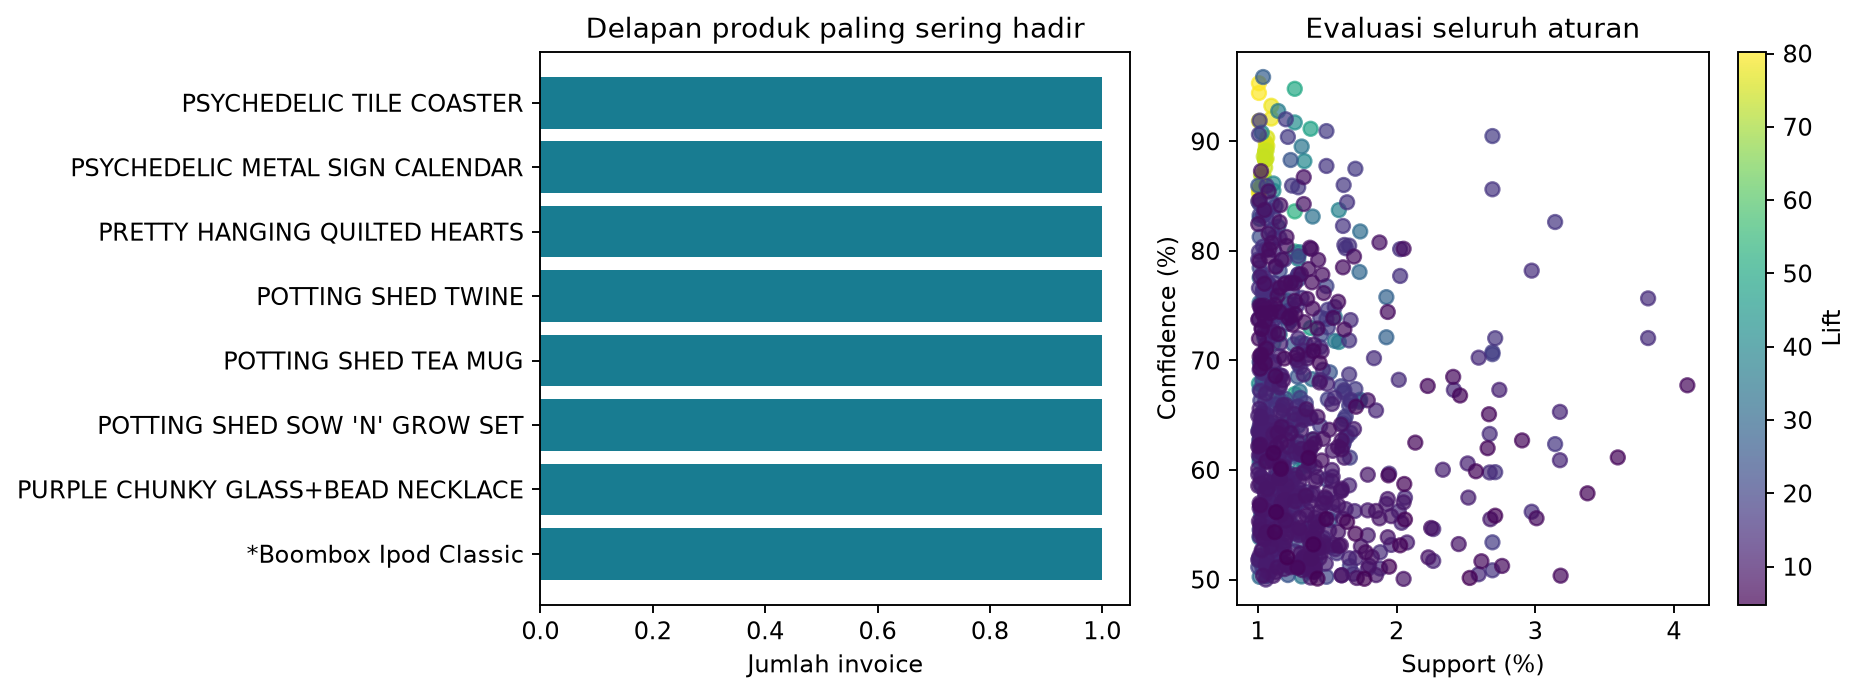

2966

In [9]:
plt.rcParams.update({'font.size': 10})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
popular = basket.sum().sort_values(ascending=False).head(8).sort_values()
axes[0].barh(popular.index, popular.values, color='#187c91')
axes[0].set_xlabel('Jumlah invoice')
axes[0].set_title('Delapan produk paling sering hadir')
sc = axes[1].scatter(rules.support*100, rules.confidence*100, c=rules.lift, cmap='viridis', alpha=.7, s=35)
axes[1].set(xlabel='Support (%)', ylabel='Confidence (%)', title='Evaluasi seluruh aturan')
fig.colorbar(sc, ax=axes[1], label='Lift')
fig.tight_layout()
fig.savefig(OUT/'visualisasi_asosiasi.png', dpi=170, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT/'visualisasi_asosiasi.png')))
summary = {'rows':len(df), 'columns':len(df.columns), 'invoices_before':int(df.InvoiceNo.nunique()),
           'clean_rows':len(clean), 'transactions':len(basket), 'products':basket.shape[1],
           'countries':int(df.Country.nunique()), 'missing':df.isna().sum().to_dict(),
           'date_start':str(df.InvoiceDate.min()), 'date_end':str(df.InvoiceDate.max()),
           'audit':audit.to_dict('records'), 'frequent':len(frequent), 'rules':len(rules),
           'interpretations':interpretations, 'top':table.head(3).to_dict('records')}
(OUT/'ringkasan_hasil.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

## 6. Kesimpulan dan keterbatasan
Aturan dengan lift tertinggi menunjukkan produk yang layak dipertimbangkan sebagai pasangan rekomendasi atau bundling. Support mengukur cakupan, confidence mengukur peluang consequent ketika antecedent hadir, dan lift membandingkannya dengan frekuensi dasar consequent. Aturan teratas tidak selalu memiliki jangkauan penjualan terbesar.

Asosiasi tidak membuktikan sebab-akibat maupun kenaikan laba. Data tahun 2010-2011, campuran negara, musim, dan pesanan besar dapat memengaruhi pola. Description dapat memiliki variasi penamaan dan beberapa entri administratif tetap dipertahankan sesuai pembersihan tugas. Validasi bisnis berikutnya dapat menggunakan StockCode, segmentasi negara/periode, dan uji promosi sebelum penerapan. Confidence untuk gabungan antecedent mensyaratkan semua item antecedent hadir.